# Q3 — K-Means Clustering and PCA, both from scratch, on the Netflix Titles Dataset
**IIIT Sri City — Machine Learning Assignment**

| Part | What we do |
|---|---|
| **3a** | Implement **K-Means from scratch** (NumPy only), run it for K = 2…6, compute the **WCSS** for each K and plot the **elbow curve** |
| **3b** | Implement **PCA from scratch** via the covariance matrix + eigenvalue decomposition: eigenvalues/eigenvectors, explained-variance ratio, cumulative-variance plot, reduction to **2 and 3 components**, 2-D visualisation |

### Why this dataset needs feature engineering
The Kaggle Netflix file is almost entirely *text/categorical* (`title`, `director`, `cast`, `country`, `listed_in`, `rating`, …). K-Means and PCA work on **numeric vectors**, so we first turn each title into a numeric feature vector:

| Feature group | Encoding | Why |
|---|---|---|
| `is_movie` | 0/1 | Movie vs TV Show is the biggest structural split |
| `release_year`, `added_year` | numeric | Age / catalogue-addition period |
| `movie_minutes`, `tv_seasons` | numeric (0 for the other type) | Length, interpreted per type |
| `rating` | grouped into Kids / Family / Teen / Adult / Unrated, one-hot | 14 raw labels are too sparse |
| `listed_in` (genres) | multi-hot, genres with ≥ 50 titles | A title can have 1–3 genres |
| `country` | multi-hot for top-15 countries + "Unknown" | Production origin |
*(optional, off by default)* TF-IDF of `description` compressed by SVD, switch `USE_TEXT_FEATURES`.

### Scaling decision (viva-critical)
K-Means and PCA are **distance/variance based**, so scale matters. We **z-score only the numeric columns**, and leave the 0/1 columns as they are. Z-scoring a rare binary column (e.g. a genre on 1 % of titles) would stretch its values to ≈ ±10 and let a tiny feature dominate the distances. The *same* matrix is used for K-Means and PCA.

### Honest caveat
There are **no ground-truth labels**, so there is no "correct" K. We use the elbow (as the brief asks), plus the silhouette score as a second opinion, and interpret clusters by profiling them.

In [1]:
# ---------------------------------------------------------------------------
# 0. Imports, configuration, reproducibility
# ---------------------------------------------------------------------------
import os, glob, random, warnings, json, time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3-D projection)

from sklearn.metrics import silhouette_score, adjusted_rand_score          # evaluation only
from sklearn.cluster import KMeans as SkKMeans                             # used ONLY to validate our implementation
from sklearn.decomposition import PCA as SkPCA                             # used ONLY to validate our implementation

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)

# project root = parent of notebooks/ (works whether Jupyter starts in notebooks/ or in the project root)
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
FIG_DIR, RES_DIR, DATA_DIR = f"{ROOT}/figures/q3", f"{ROOT}/results", f"{ROOT}/data"
for d in (FIG_DIR, RES_DIR):
    os.makedirs(d, exist_ok=True)

# ---- configuration -------------------------------------------------------
K_REQUIRED = [2, 3, 4, 5, 6]            # required by the assignment
K_EXTENDED = list(range(1, 11))         # extra range, gives a clearer elbow picture
MIN_GENRE_COUNT = 50                    # keep genres with at least this many titles
TOP_COUNTRIES = 15
USE_TEXT_FEATURES = False               # True -> add 50 TF-IDF/SVD dimensions from `description`
K_FINAL = None                          # None -> use the automatic elbow estimate for K=2..6; or set e.g. K_FINAL = 4

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
def savefig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", bbox_inches="tight")

## 1. Load the data
Kaggle needs a login for manual downloads, so: put `netflix_titles.csv` into `data/` (download from the Kaggle page → *Download*). If it isn't there we try `kagglehub` (works for public datasets when internet is available).

In [2]:
def load_netflix():
    paths = sorted(glob.glob(f"{DATA_DIR}/*netflix*.csv"))
    if paths:
        return pd.read_csv(paths[0]), paths[0]
    try:
        import kagglehub
        folder = kagglehub.dataset_download("shivamb/netflix-shows")
        csvs = glob.glob(os.path.join(folder, "*.csv"))
        return pd.read_csv(csvs[0]), csvs[0]
    except Exception as e:
        raise FileNotFoundError("Download netflix_titles.csv from Kaggle (shivamb/netflix-shows) into the data/ folder.") from e

raw, source = load_netflix()
print("Loaded from:", source, "| shape:", raw.shape)
print("Columns:", list(raw.columns))
display(raw.head(3))
print("\nMissing values per column:"); print(raw.isna().sum()[raw.isna().sum() > 0].to_string())

Loaded from: C:\Users\user\OneDrive\Desktop\ml_assignment/data\netflix_titles.csv | shape: (8807, 12)
Columns: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...



Missing values per column:
director      2634
cast           825
country        831
date_added      10
rating           4
duration         3


## 2. Cleaning and feature engineering
Known quirk of this file: a handful of rows have the *duration* (e.g. "74 min") stored in the `rating` column and an empty `duration`. We detect and repair those rows rather than silently dropping them.

In [3]:
df = raw.copy()
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].astype("string").str.strip()

# 2.1 repair misplaced durations
mis = df["rating"].str.contains(r"\bmin\b", na=False)
print("Rows with duration stored in the rating column:", int(mis.sum()))
fix = mis & df["duration"].isna()
df.loc[fix, "duration"] = df.loc[fix, "rating"]
df.loc[mis, "rating"] = pd.NA

# 2.2 numeric columns
df["is_movie"] = (df["type"] == "Movie").astype(int)
minutes = pd.to_numeric(df["duration"].str.extract(r"(\d+)\s*min", expand=False), errors="coerce")
seasons = pd.to_numeric(df["duration"].str.extract(r"(\d+)\s*Season", expand=False), errors="coerce")
df["movie_minutes"] = np.where(df["is_movie"] == 1, minutes, 0.0)
df["tv_seasons"] = np.where(df["is_movie"] == 0, seasons, 0.0)
df.loc[(df["is_movie"] == 1) & df["movie_minutes"].isna(), "movie_minutes"] = np.nanmedian(minutes[df["is_movie"] == 1])
df.loc[(df["is_movie"] == 0) & df["tv_seasons"].isna(), "tv_seasons"] = np.nanmedian(seasons[df["is_movie"] == 0])
# winsorise extreme lengths (1st–99th percentile within type) so outliers cannot dominate distances
for col, mask in [("movie_minutes", df["is_movie"] == 1), ("tv_seasons", df["is_movie"] == 0)]:
    lo, hi = df.loc[mask, col].quantile([.01, .99])
    df.loc[mask, col] = df.loc[mask, col].clip(lo, hi)

df["release_year"] = pd.to_numeric(df["release_year"], errors="coerce")
added = pd.to_datetime(df["date_added"], errors="coerce", format="mixed")
df["added_year"] = added.dt.year.fillna(added.dt.year.median())
df["release_year"] = df["release_year"].fillna(df["release_year"].median())

# 2.3 rating groups
RATING_MAP = {"TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "G": "Kids", "TV-G": "Kids",
              "PG": "Family", "TV-PG": "Family", "PG-13": "Teen", "TV-14": "Teen",
              "R": "Adult", "TV-MA": "Adult", "NC-17": "Adult"}
df["rating_group"] = df["rating"].map(RATING_MAP).fillna("Unrated").astype(str)
R = pd.get_dummies(df["rating_group"], prefix="rating").astype(int)

# 2.4 genres (multi-hot)
split_list = lambda s: [t.strip() for t in str(s).split(",") if t.strip() and t != "<NA>"]
genre_lists = df["listed_in"].apply(split_list)
gcount = Counter(g for gl in genre_lists for g in gl)
keep_genres = [g for g, c in gcount.most_common() if c >= MIN_GENRE_COUNT]
G = pd.DataFrame({f"genre_{g}": genre_lists.apply(lambda gl, g=g: int(g in gl)) for g in keep_genres})
print(f"Genres kept: {len(keep_genres)} of {len(gcount)}")

# 2.5 countries (multi-hot, top-N + unknown)
country_lists = df["country"].apply(split_list)
ccount = Counter(c for cl in country_lists for c in cl)
keep_countries = [c for c, _ in ccount.most_common(TOP_COUNTRIES)]
C = pd.DataFrame({f"country_{c}": country_lists.apply(lambda cl, c=c: int(c in cl)) for c in keep_countries})
C["country_Unknown"] = (country_lists.apply(len) == 0).astype(int)

# 2.6 optional text features
T = pd.DataFrame(index=df.index)
if USE_TEXT_FEATURES:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.decomposition import TruncatedSVD
    tf = TfidfVectorizer(stop_words="english", min_df=5, max_features=5000).fit_transform(df["description"].fillna(""))
    T = pd.DataFrame(TruncatedSVD(50, random_state=SEED).fit_transform(tf), columns=[f"text_svd_{i}" for i in range(50)], index=df.index)

NUM_COLS = ["release_year", "added_year", "movie_minutes", "tv_seasons"] + list(T.columns)
BIN_COLS = ["is_movie"] + list(R.columns) + list(G.columns) + list(C.columns)
F = pd.concat([df[["is_movie", "release_year", "added_year", "movie_minutes", "tv_seasons"]], R, G, C, T], axis=1)

# 2.7 scale: z-score numeric columns only (binary columns stay 0/1)
mu, sd = F[NUM_COLS].mean(), F[NUM_COLS].std(ddof=0).replace(0, 1)
F_scaled = F.copy(); F_scaled[NUM_COLS] = (F[NUM_COLS] - mu) / sd
FEATURE_NAMES = list(F_scaled.columns)
X = F_scaled.values.astype(float)
assert np.isfinite(X).all()
print(f"\nFinal feature matrix: {X.shape[0]} titles × {X.shape[1]} features "
      f"({len(NUM_COLS)} numeric z-scored, {len(BIN_COLS)} binary)")
pd.Series(FEATURE_NAMES).to_csv(f"{RES_DIR}/q3_feature_list.csv", index=False, header=["feature"])
F_scaled.head(3).round(2)

Rows with duration stored in the rating column: 3


Genres kept: 40 of 42

Final feature matrix: 8807 titles × 66 features (4 numeric z-scored, 62 binary)


,is_movie,release_year,added_year,movie_minutes,tv_seasons,rating_Adult,rating_Family,rating_Kids,rating_Teen,rating_Unrated,...,country_Spain,country_South Korea,country_Germany,country_Mexico,country_China,country_Australia,country_Egypt,country_Turkey,country_Hong Kong,country_Unknown
0,1,0.66,1.35,0.41,-0.47,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0.77,1.35,-1.35,1.31,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0.77,1.35,-1.35,0.42,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1


## 3a. K-Means from scratch
**Objective:** choose K centroids μ₁…μ_K to minimise the **within-cluster sum of squares**
WCSS = Σₖ Σ_{x∈Cₖ} ‖x − μₖ‖²  (also called *inertia*).

**Lloyd's algorithm**
1. **Initialise** K centroids (we implement both *random* and **k-means++**: first centre uniformly at random, each next centre sampled with probability ∝ squared distance to the nearest chosen centre → spread-out starts).
2. **Assign** every point to its nearest centroid (Euclidean).
3. **Update** each centroid to the mean of its points.
4. Repeat 2–3 until the centroids stop moving (shift below tolerance) or `max_iter` is reached. WCSS never increases between iterations, so the algorithm always converges — but only to a **local** minimum, hence we run it **`n_init` times** from different starts and keep the lowest WCSS.

**Implementation notes:** distances use ‖x−c‖² = ‖x‖² − 2x·c + ‖c‖² (one matrix multiplication instead of loops); an *empty cluster* is repaired by moving that centroid to the point currently farthest from its centroid.

In [4]:
class KMeansScratch:
    """K-Means (Lloyd's algorithm) using NumPy only."""
    def __init__(self, n_clusters=3, init="k-means++", n_init=10, max_iter=300, tol=1e-4, random_state=None):
        self.n_clusters, self.init, self.n_init = n_clusters, init, n_init
        self.max_iter, self.tol, self.random_state = max_iter, tol, random_state

    # --- helpers -----------------------------------------------------------
    def _init_centroids(self, X, rng):
        n, k = len(X), self.n_clusters
        if self.init == "random":
            return X[rng.choice(n, size=k, replace=False)].copy()
        centroids = [X[rng.integers(n)]]
        d2 = ((X - centroids[0]) ** 2).sum(1)
        for _ in range(1, k):
            total = d2.sum()
            i = rng.choice(n, p=d2 / total) if total > 0 else rng.integers(n)
            centroids.append(X[i])
            d2 = np.minimum(d2, ((X - X[i]) ** 2).sum(1))
        return np.array(centroids)

    @staticmethod
    def _assign(X, x2, C):
        d2 = x2[:, None] - 2.0 * X @ C.T + (C ** 2).sum(1)[None, :]
        np.maximum(d2, 0, out=d2)                         # guard tiny negative values from rounding
        labels = d2.argmin(1)
        point_d2 = d2[np.arange(len(X)), labels]
        return labels, point_d2

    def _single_run(self, X, x2, rng):
        k = self.n_clusters
        C = self._init_centroids(X, rng)
        tol_abs = self.tol * np.mean(np.var(X, axis=0))   # same scale-free tolerance idea as scikit-learn
        history = []
        for it in range(self.max_iter):
            labels, point_d2 = self._assign(X, x2, C)
            history.append(point_d2.sum())
            newC = np.empty_like(C)
            counts = np.bincount(labels, minlength=k)
            for j in range(k):
                if counts[j] == 0:                        # empty cluster -> re-seed at the worst-fit point
                    far = point_d2.argmax(); newC[j] = X[far]; point_d2[far] = 0
                else:
                    newC[j] = X[labels == j].mean(0)
            shift = ((newC - C) ** 2).sum()
            C = newC
            if shift <= tol_abs:
                break
        labels, point_d2 = self._assign(X, x2, C)         # final assignment for the final centroids
        return C, labels, point_d2.sum(), it + 1, history

    # --- public API --------------------------------------------------------
    def fit(self, X):
        X = np.asarray(X, float); x2 = (X ** 2).sum(1)
        rng = np.random.default_rng(self.random_state)
        best = None
        for _ in range(self.n_init):
            run = self._single_run(X, x2, rng)
            if best is None or run[2] < best[2]:
                best = run
        self.cluster_centers_, self.labels_, self.inertia_, self.n_iter_, self.inertia_history_ = best
        return self

    def predict(self, X):
        X = np.asarray(X, float)
        return self._assign(X, (X ** 2).sum(1), self.cluster_centers_)[0]

# quick smoke test on 3 obvious blobs
rs = np.random.default_rng(0)
blobs = np.vstack([rs.normal(m, .4, (150, 2)) for m in [(0, 0), (4, 4), (0, 5)]])
km_t = KMeansScratch(3, random_state=0).fit(blobs)
print("Smoke test on 3 well-separated blobs → cluster sizes:", np.bincount(km_t.labels_), "| WCSS:", round(km_t.inertia_, 1))

Smoke test on 3 well-separated blobs → cluster sizes: [150 150 150] | WCSS: 135.7


### 3a-i. Validation: is our implementation correct?
We compare against `sklearn.cluster.KMeans` on our data. WCSS from the two implementations should be nearly identical, and the partitions should agree (Adjusted Rand Index close to 1; K-Means is non-convex so tiny differences from different local minima can occur). *scikit-learn is used only as an independent check — all results below come from our own class.*

In [5]:
rows = []
for k in K_REQUIRED:
    ours = KMeansScratch(k, n_init=10, random_state=SEED).fit(X)
    sk = SkKMeans(k, n_init=10, random_state=SEED).fit(X)
    rows.append({"K": k, "WCSS (ours)": ours.inertia_, "WCSS (sklearn)": sk.inertia_,
                 "rel. diff %": 100 * (ours.inertia_ - sk.inertia_) / sk.inertia_,
                 "ARI(ours, sklearn)": adjusted_rand_score(ours.labels_, sk.labels_), "iterations (ours)": ours.n_iter_})
val = pd.DataFrame(rows).set_index("K"); display(val.round(4))
val.round(6).to_csv(f"{RES_DIR}/q3_kmeans_validation_vs_sklearn.csv")

,WCSS (ours),WCSS (sklearn),rel. diff %,"ARI(ours, sklearn)",iterations (ours)
K,,,,,
2,50994.7659,50994.7659,0.0000,1.0000,7
3,45671.9165,45671.9992,-0.0002,0.9998,15
4,41917.8861,41917.8861,-0.0000,1.0000,16
5,38700.2009,38700.2593,-0.0002,0.9985,14
6,36900.6579,36900.6496,0.0000,0.9997,23


### 3a-ii. Why `n_init` and k-means++ matter (initialisation experiment)
40 single runs (n_init = 1) from random vs k-means++ starts at K = 4. The spread of the final WCSS shows how sensitive Lloyd's algorithm is to its starting point.

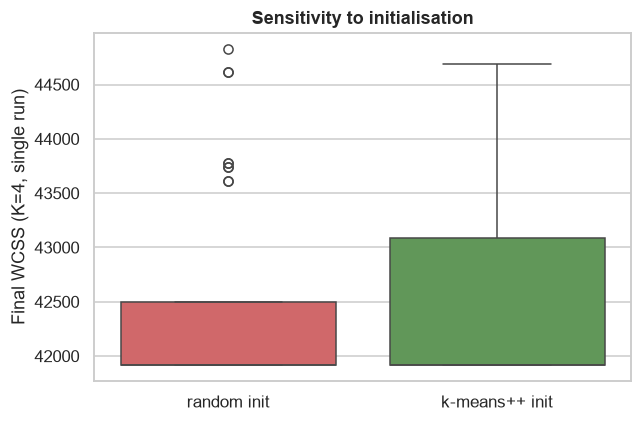

random: mean=42437, sd=901, best=41918 | k-means++: mean=42456, sd=794, best=41918


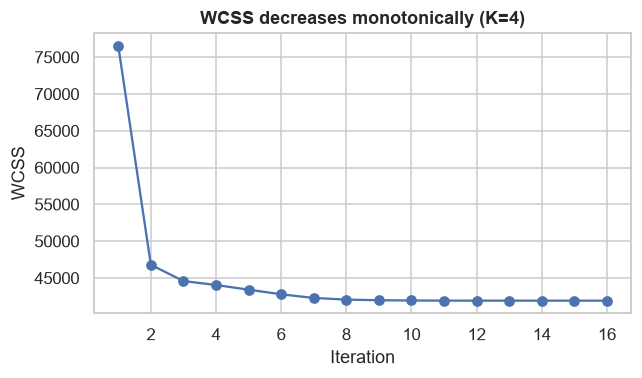

In [6]:
K_DEMO = 4
w_rand = [KMeansScratch(K_DEMO, init="random", n_init=1, random_state=s).fit(X).inertia_ for s in range(40)]
w_pp = [KMeansScratch(K_DEMO, init="k-means++", n_init=1, random_state=s).fit(X).inertia_ for s in range(40)]
plt.figure(figsize=(6, 4))
sns.boxplot(data=[w_rand, w_pp], palette=["#E15759", "#59A14F"]); plt.xticks([0, 1], ["random init", "k-means++ init"])
plt.ylabel(f"Final WCSS (K={K_DEMO}, single run)"); plt.title("Sensitivity to initialisation"); plt.tight_layout(); savefig("01_init_sensitivity"); plt.show()
print(f"random: mean={np.mean(w_rand):.0f}, sd={np.std(w_rand):.0f}, best={np.min(w_rand):.0f} | k-means++: mean={np.mean(w_pp):.0f}, sd={np.std(w_pp):.0f}, best={np.min(w_pp):.0f}")

conv = KMeansScratch(K_DEMO, n_init=1, random_state=SEED).fit(X).inertia_history_
plt.figure(figsize=(6, 3.6)); plt.plot(range(1, len(conv) + 1), conv, "o-"); plt.xlabel("Iteration"); plt.ylabel("WCSS")
plt.title(f"WCSS decreases monotonically (K={K_DEMO})"); plt.tight_layout(); savefig("02_kmeans_convergence"); plt.show()

### 3a-iii. WCSS for K = 2,3,4,5,6 and the elbow curve (**required**)
WCSS always decreases as K grows (K = n would give 0), so we look for the **elbow**: the K after which extra clusters give diminishing returns. We also compute the **silhouette score** (mean of (b−a)/max(a,b) over points; −1…1, higher is better) and a simple automatic elbow detector (the point farthest from the straight line joining the first and last points of the curve).

WCSS for the required K values:


,WCSS,drop vs K-1 (%),silhouette
K,,,
2,50994.766,23.608,0.257
3,45671.917,10.438,0.254
4,41917.886,8.220,0.149
5,38700.201,7.676,0.160
6,36900.658,4.650,0.143


Automatic elbow estimate: K=4 (range 2–6), K=3 (range 1–10) | best silhouette in 2–6: K=2


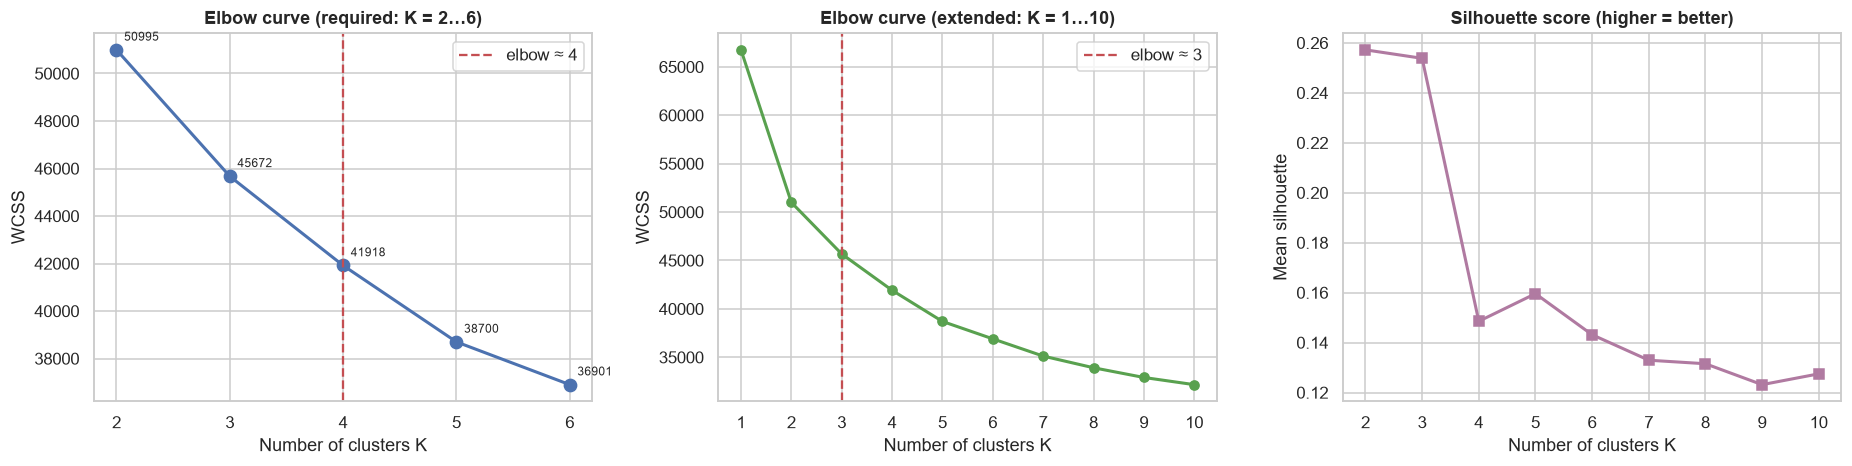

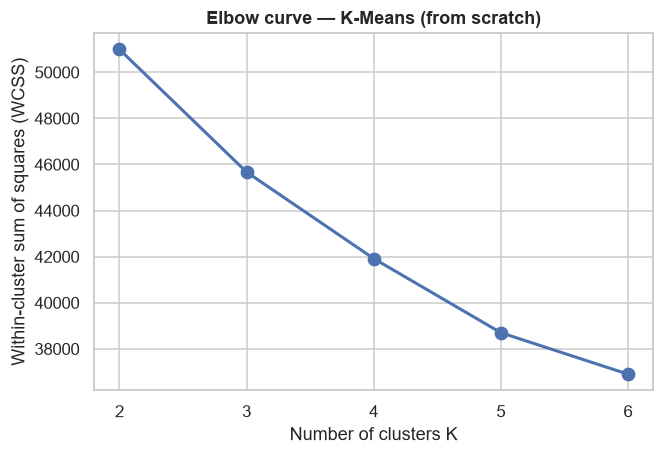

In [7]:
fits, wcss, sil = {}, {}, {}
for k in K_EXTENDED:
    m = KMeansScratch(k, n_init=10, random_state=SEED).fit(X)
    fits[k], wcss[k] = m, m.inertia_
    if k >= 2:
        sil[k] = silhouette_score(X, m.labels_, sample_size=3000, random_state=SEED)

def knee(ks, ys):
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0]); y = (np.array(ys) - ys[-1]) / (ys[0] - ys[-1])
    return ks[int(np.argmax(np.abs(x + y - 1) / np.sqrt(2)))]       # distance to the line from (0,1) to (1,0)

wc_req = pd.DataFrame({"K": K_REQUIRED, "WCSS": [wcss[k] for k in K_REQUIRED]}).set_index("K")
wc_req["drop vs K-1 (%)"] = [100 * (wcss[k - 1] - wcss[k]) / wcss[k - 1] for k in K_REQUIRED]
wc_req["silhouette"] = [sil[k] for k in K_REQUIRED]
print("WCSS for the required K values:"); display(wc_req.round(3))
wc_req.round(6).to_csv(f"{RES_DIR}/q3_wcss_required.csv")
pd.DataFrame({"K": K_EXTENDED, "WCSS": [wcss[k] for k in K_EXTENDED], "silhouette": [sil.get(k, np.nan) for k in K_EXTENDED]}).round(6).to_csv(f"{RES_DIR}/q3_wcss_extended.csv", index=False)

knee_req, knee_ext = knee(K_REQUIRED, [wcss[k] for k in K_REQUIRED]), knee(K_EXTENDED, [wcss[k] for k in K_EXTENDED])
best_sil_k = max(K_REQUIRED, key=lambda k: sil[k])
print(f"Automatic elbow estimate: K={knee_req} (range 2–6), K={knee_ext} (range 1–10) | best silhouette in 2–6: K={best_sil_k}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
axes[0].plot(K_REQUIRED, [wcss[k] for k in K_REQUIRED], "o-", lw=2, ms=8); axes[0].axvline(knee_req, color="r", ls="--", label=f"elbow ≈ {knee_req}")
for k in K_REQUIRED: axes[0].annotate(f"{wcss[k]:.0f}", (k, wcss[k]), textcoords="offset points", xytext=(5, 6), fontsize=8)
axes[0].set_title("Elbow curve (required: K = 2…6)"); axes[0].set_xlabel("Number of clusters K"); axes[0].set_ylabel("WCSS"); axes[0].set_xticks(K_REQUIRED); axes[0].legend()
axes[1].plot(K_EXTENDED, [wcss[k] for k in K_EXTENDED], "o-", lw=2, color="#59A14F"); axes[1].axvline(knee_ext, color="r", ls="--", label=f"elbow ≈ {knee_ext}")
axes[1].set_title("Elbow curve (extended: K = 1…10)"); axes[1].set_xlabel("Number of clusters K"); axes[1].set_ylabel("WCSS"); axes[1].set_xticks(K_EXTENDED); axes[1].legend()
ks2 = [k for k in K_EXTENDED if k >= 2]
axes[2].plot(ks2, [sil[k] for k in ks2], "s-", lw=2, color="#B07AA1"); axes[2].set_title("Silhouette score (higher = better)")
axes[2].set_xlabel("Number of clusters K"); axes[2].set_ylabel("Mean silhouette"); axes[2].set_xticks(ks2)
plt.tight_layout(); savefig("03_elbow_curve"); plt.show()

# A clean, stand-alone version of the required plot (for the report)
plt.figure(figsize=(6.2, 4.3)); plt.plot(K_REQUIRED, [wcss[k] for k in K_REQUIRED], "o-", lw=2, ms=8)
plt.xlabel("Number of clusters K"); plt.ylabel("Within-cluster sum of squares (WCSS)"); plt.title("Elbow curve — K-Means (from scratch)")
plt.xticks(K_REQUIRED); plt.tight_layout(); savefig("03b_elbow_required_only"); plt.show()

### 3a-iv. Choosing the final K and interpreting the clusters
The elbow of a real, mixed-type dataset is usually *soft*. By default we take the **elbow estimate** for K = 2…6 (as the brief frames the task) and use the silhouette score as supporting evidence. Note that silhouette often favours K = 2, which on this data is just "movies vs TV shows" — a valid but not very informative split. You can override the choice with `K_FINAL` (e.g. `K_FINAL = 4`). We then **profile** the clusters: what do the titles inside each cluster have in common?

Final K = 4  | WCSS = 41917.9 | silhouette = 0.149 | sizes = [3286, 572, 2655, 2294]


,size,share %,% movies,median release yr,median movie min,median TV seasons,top rating group,top genres (share),most distinctive genres (lift),top countries
cluster,,,,,,,,,,
0,3286,37.3,100.0,2018.0,99.0,NaN,Adult,"International Movies 45%, Dramas 41%, Comedies 30%","Romantic Movies ×1.7, Children & Family Movies ×1.7, Thrillers ×1.6","United States 43%, India 13%"
1,572,6.5,96.9,1992.0,109.0,1.0,Teen,"Dramas 41%, Comedies 33%, International Movies 32%","Classic Movies ×15.3, Cult Movies ×10.4, Action & Adventure ×3.0","United States 60%, India 18%"
2,2655,30.1,0.0,2018.0,NaN,1.0,Adult,"International TV Shows 51%, TV Dramas 29%, TV Comedies 22%","Romantic TV Shows ×3.3, Korean TV Shows ×3.3, TV Action & Adventure ×3.3","United States 35%, Unknown 15%"
3,2294,26.0,99.9,2016.0,95.0,1.0,Adult,"International Movies 47%, Dramas 38%, Comedies 22%","Stand-Up Comedy ×2.2, Documentaries ×2.0, Independent Movies ×1.6","United States 43%, India 19%"


Cluster 0 example titles: ['Cop Car', 'Danur: I Can See Ghosts', "There's Something in the Water", 'Rogue Warfare', 'Sorry To Disturb']
Cluster 1 example titles: ['The Lord of the Rings: The Return of the King', 'The Long Riders', 'Edge of Seventeen', 'Money Talks', 'Thelonious Monk: Straight, No Chaser']
Cluster 2 example titles: ['Curon', 'Friday Night Lights', 'Memories of the Alhambra', 'Brainchild', 'Julie and the Phantoms']
Cluster 3 example titles: ['Family Blood', 'Blackway', 'The Meaning of Monty Python', 'Sarah Silverman A Speck of Dust', 'Rory Scovel Tries Stand-Up for the First Time']


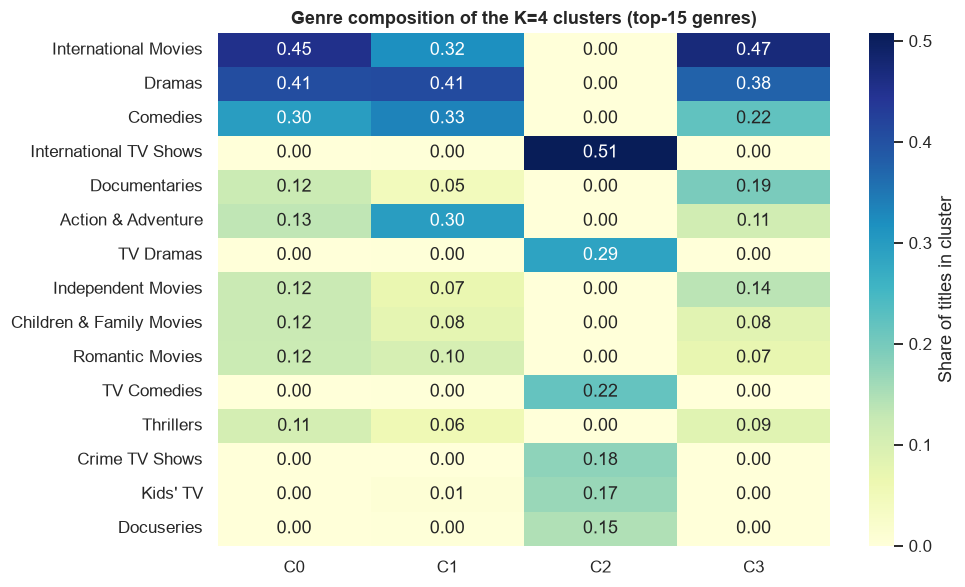

In [8]:
K_FINAL_USED = K_FINAL if K_FINAL is not None else knee_req
km = fits[K_FINAL_USED] if K_FINAL_USED in fits else KMeansScratch(K_FINAL_USED, n_init=10, random_state=SEED).fit(X)
labels = km.labels_
print(f"Final K = {K_FINAL_USED}  | WCSS = {km.inertia_:.1f} | silhouette = {sil.get(K_FINAL_USED, np.nan):.3f} | sizes = {np.bincount(labels).tolist()}")

prof_df = df.assign(cluster=labels)
overall_genre = G.mean()
rows, ex = [], {}
for c in range(K_FINAL_USED):
    m = (labels == c)
    gshare = G[m].mean().sort_values(ascending=False)
    lift = (G[m].mean() / overall_genre.replace(0, np.nan)).where(G[m].mean() >= 0.05).dropna().sort_values(ascending=False)
    cshare = C[m].mean().sort_values(ascending=False)
    rows.append({"cluster": c, "size": int(m.sum()), "share %": round(100 * m.mean(), 1),
                 "% movies": round(100 * df.loc[m, "is_movie"].mean(), 1),
                 "median release yr": df.loc[m, "release_year"].median(),
                 "median movie min": df.loc[m & (df["is_movie"] == 1), "movie_minutes"].median(),
                 "median TV seasons": df.loc[m & (df["is_movie"] == 0), "tv_seasons"].median(),
                 "top rating group": df.loc[m, "rating_group"].value_counts().index[0],
                 "top genres (share)": ", ".join(f"{g.replace('genre_','')} {v:.0%}" for g, v in gshare.head(3).items()),
                 "most distinctive genres (lift)": ", ".join(f"{g.replace('genre_','')} ×{v:.1f}" for g, v in lift.head(3).items()),
                 "top countries": ", ".join(f"{g.replace('country_','')} {v:.0%}" for g, v in cshare.head(2).items())})
    ex[c] = prof_df.loc[m, "title"].sample(min(5, int(m.sum())), random_state=SEED).tolist()
profile = pd.DataFrame(rows).set_index("cluster")
pd.set_option("display.max_colwidth", 80); display(profile)
profile.to_csv(f"{RES_DIR}/q3_cluster_profiles.csv")
for c, t in ex.items():
    print(f"Cluster {c} example titles: {t}")

top_g = G.mean().sort_values(ascending=False).head(15).index
share = pd.DataFrame({f"C{c}": G.loc[labels == c, top_g].mean() for c in range(K_FINAL_USED)})
share.index = [i.replace("genre_", "") for i in share.index]
plt.figure(figsize=(1.3 * K_FINAL_USED + 4, 5.5)); sns.heatmap(share, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "Share of titles in cluster"})
plt.title(f"Genre composition of the K={K_FINAL_USED} clusters (top-15 genres)"); plt.tight_layout(); savefig("04_cluster_genre_heatmap"); plt.show()

## 3b. PCA from scratch (covariance matrix + eigenvalue decomposition)
**Idea:** find orthogonal directions (principal components) along which the data vary the most.

**Algorithm**
1. **Centre** the data: X_c = X − mean (the features are already on comparable scales — see the scaling decision above).
2. **Covariance matrix** Σ = X_cᵀX_c / (n−1)  (size p×p, symmetric, positive semi-definite).
3. **Eigen-decomposition** Σ v = λ v. Each eigenvector **v** is a principal-component direction; its eigenvalue **λ** is the variance of the data along it. We use `np.linalg.eigh` (not `eig`) because Σ is symmetric: it is faster, guarantees *real* eigenvalues and *orthonormal* eigenvectors.
4. **Sort** eigenpairs by λ in descending order.
5. **Explained-variance ratio** of component i = λᵢ / Σⱼ λⱼ; cumulative sum tells how many components are needed to keep e.g. 90 % of the variance.
6. **Project**: Z = X_c · V_k keeps the first k components → dimensionality reduction from p to k.

In [9]:
class PCAScratch:
    """PCA via covariance matrix and eigenvalue decomposition (NumPy only)."""
    def fit(self, X):
        X = np.asarray(X, float)
        self.mean_ = X.mean(axis=0)
        Xc = X - self.mean_
        self.cov_ = np.cov(Xc, rowvar=False)                      # (p, p), divides by n-1
        eigvals, eigvecs = np.linalg.eigh(self.cov_)              # ascending order
        order = np.argsort(eigvals)[::-1]
        eigvals, eigvecs = eigvals[order], eigvecs[:, order]
        eigvals = np.clip(eigvals, 0, None)                       # tiny negatives from round-off -> 0
        # deterministic sign convention: the largest-magnitude loading of every component is positive
        signs = np.sign(eigvecs[np.abs(eigvecs).argmax(axis=0), np.arange(eigvecs.shape[1])]); signs[signs == 0] = 1
        eigvecs = eigvecs * signs
        self.eigenvalues_ = eigvals
        self.components_ = eigvecs.T                              # row i = i-th principal axis
        self.explained_variance_ratio_ = eigvals / eigvals.sum()
        self.cumulative_variance_ = np.cumsum(self.explained_variance_ratio_)
        return self
    def transform(self, X, n_components):
        return (np.asarray(X, float) - self.mean_) @ self.components_[:n_components].T
    def inverse_transform(self, Z):
        return Z @ self.components_[:Z.shape[1]] + self.mean_

pca = PCAScratch().fit(X)
p = X.shape[1]
print(f"Covariance matrix: {pca.cov_.shape}, symmetric: {np.allclose(pca.cov_, pca.cov_.T)}")

Covariance matrix: (66, 66), symmetric: True


### 3b-i. Eigenvalues, eigenvectors and correctness checks
We verify the mathematics numerically (these checks are good viva material):
* Σ v = λ v for every eigenpair (residual ≈ 0)
* eigenvectors are orthonormal (VᵀV = I)
* the eigenvalues sum to the trace of Σ (total variance is preserved)
* agreement with `sklearn.decomposition.PCA` (explained-variance ratios, and the axes up to sign)

In [10]:
V = pca.components_.T
resid = np.abs(pca.cov_ @ V - V * pca.eigenvalues_).max()
print(f"max |Σv − λv|                : {resid:.2e}")
print(f"max |VᵀV − I|                : {np.abs(V.T @ V - np.eye(p)).max():.2e}")
print(f"sum(eigenvalues) vs trace(Σ) : {pca.eigenvalues_.sum():.6f} vs {np.trace(pca.cov_):.6f}")

sk_p = SkPCA().fit(X)
print(f"EVR matches sklearn          : {np.allclose(pca.explained_variance_ratio_, sk_p.explained_variance_ratio_, atol=1e-8)}")
cos = np.abs((pca.components_[:10] * sk_p.components_[:10]).sum(1))
print("|cos| between our and sklearn axes (first 10, 1.0 = same axis up to sign):", np.round(cos, 4))

ev = pd.DataFrame({"eigenvalue": pca.eigenvalues_, "explained_variance_ratio": pca.explained_variance_ratio_, "cumulative": pca.cumulative_variance_},
                  index=[f"PC{i+1}" for i in range(p)])
print("\nTop-10 eigenvalues and explained variance:"); display(ev.head(10).round(4))
ev.round(8).to_csv(f"{RES_DIR}/q3_pca_variance.csv")

max |Σv − λv|                : 7.84e-16
max |VᵀV − I|                : 2.89e-15
sum(eigenvalues) vs trace(Σ) : 7.580484 vs 7.580484
EVR matches sklearn          : True
|cos| between our and sklearn axes (first 10, 1.0 = same axis up to sign): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Top-10 eigenvalues and explained variance:


,eigenvalue,explained_variance_ratio,cumulative
PC1,2.1223,0.2800,0.2800
PC2,1.0890,0.1437,0.4236
PC3,0.8895,0.1173,0.5410
PC4,0.4459,0.0588,0.5998
PC5,0.3844,0.0507,0.6505
PC6,0.3341,0.0441,0.6946
PC7,0.2102,0.0277,0.7223
PC8,0.1675,0.0221,0.7444
PC9,0.1500,0.0198,0.7642
PC10,0.1360,0.0179,0.7822


### 3b-ii. Explained-variance ratio and cumulative explained variance (**required plot**)

Components needed → {'80%': 12, '90%': 23, '95%': 34} (out of 66)


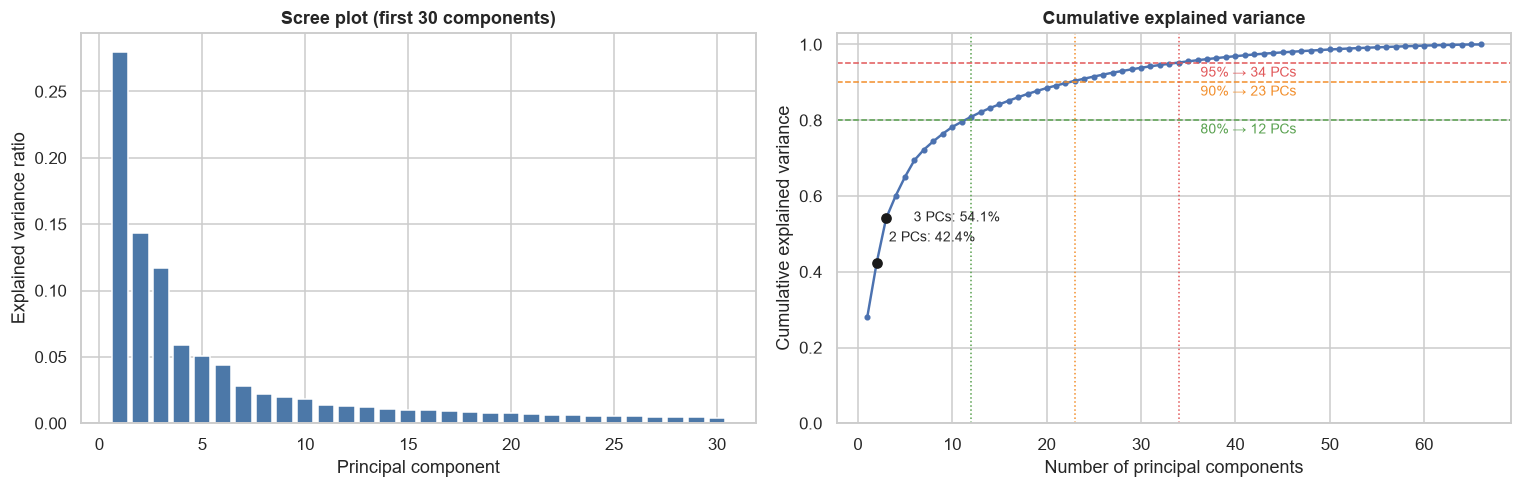

In [11]:
n_for = {t: int(np.searchsorted(pca.cumulative_variance_, t) + 1) for t in (0.80, 0.90, 0.95)}
print("Components needed →", {f"{int(t*100)}%": n for t, n in n_for.items()}, f"(out of {p})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
nshow = min(p, 30)
axes[0].bar(range(1, nshow + 1), pca.explained_variance_ratio_[:nshow], color="#4C78A8"); axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Scree plot (first 30 components)")
axes[1].plot(range(1, p + 1), pca.cumulative_variance_, "o-", ms=3, lw=1.6)
for t, col in [(0.80, "#59A14F"), (0.90, "#F28E2B"), (0.95, "#E15759")]:
    axes[1].axhline(t, color=col, ls="--", lw=1); axes[1].axvline(n_for[t], color=col, ls=":", lw=1)
    axes[1].text(p * 0.55, t - 0.035, f"{int(t*100)}% → {n_for[t]} PCs", color=col, fontsize=9)
axes[1].scatter([2, 3], pca.cumulative_variance_[[1, 2]], color="k", zorder=5)
axes[1].annotate(f"2 PCs: {pca.cumulative_variance_[1]:.1%}", (2, pca.cumulative_variance_[1]), xytext=(8, 14), textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="-"))
axes[1].annotate(f"3 PCs: {pca.cumulative_variance_[2]:.1%}", (3, pca.cumulative_variance_[2]), xytext=(18, -2), textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="-"))
axes[1].set_xlabel("Number of principal components"); axes[1].set_ylabel("Cumulative explained variance"); axes[1].set_title("Cumulative explained variance"); axes[1].set_ylim(0, 1.03)
plt.tight_layout(); savefig("05_pca_scree_and_cumulative"); plt.show()

### 3b-iii. Reduce the feature space to 2 and to 3 principal components
We report the **variance retained** and the **reconstruction error** (mean squared difference between the original and the data rebuilt from k components) — a direct measure of the information thrown away.

In [12]:
Z2, Z3 = pca.transform(X, 2), pca.transform(X, 3)
print(f"Original: {X.shape} → 2 PCs: {Z2.shape} | 3 PCs: {Z3.shape}")
red = []
for k in (2, 3):
    Xhat = pca.inverse_transform(pca.transform(X, k))
    red.append({"components": k, "shape": str(pca.transform(X, k).shape), "variance retained %": 100 * pca.cumulative_variance_[k - 1],
                "reconstruction MSE": float(np.mean((X - Xhat) ** 2)),
                "dims removed": p - k})
red = pd.DataFrame(red).set_index("components"); display(red.round(4)); red.round(6).to_csv(f"{RES_DIR}/q3_pca_reduction_summary.csv")
np.save(f"{RES_DIR}/q3_pca_2d.npy", Z2); np.save(f"{RES_DIR}/q3_pca_3d.npy", Z3)
assert np.allclose(Z2.var(axis=0, ddof=1), pca.eigenvalues_[:2]), "variance of projected data must equal the eigenvalues"
print("Check passed: variance of the projected coordinates equals the corresponding eigenvalues.")

Original: (8807, 66) → 2 PCs: (8807, 2) | 3 PCs: (8807, 3)


,shape,variance retained %,reconstruction MSE,dims removed
components,,,,
2,"(8807, 2)",42.3635,0.0662,64
3,"(8807, 3)",54.0979,0.0527,63


Check passed: variance of the projected coordinates equals the corresponding eigenvalues.


### 3b-iv. Visualise the data on the first two principal components
Left: coloured by content type; middle: by our K-Means clusters; right: by rating group. If the clusters occupy different regions of PC1–PC2, K-Means has found structure that PCA also sees.

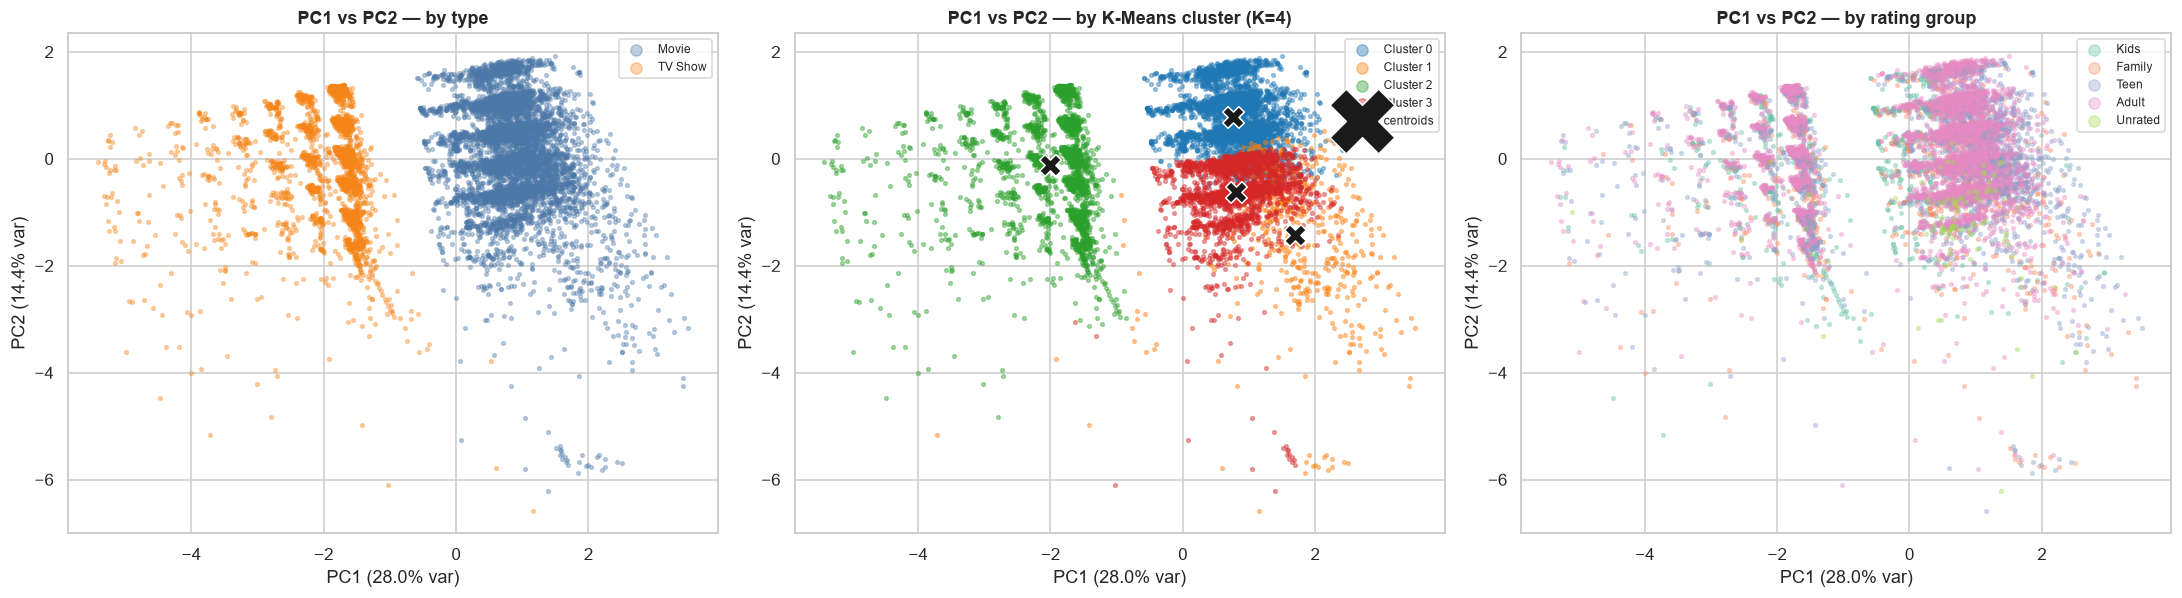

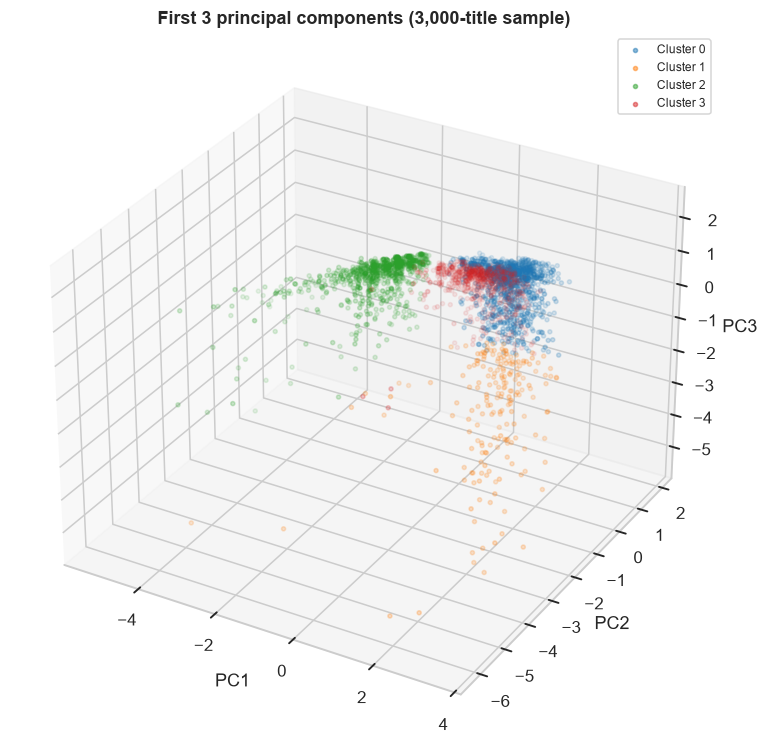

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.6))
tcol = df["type"].astype(str).values
for t, col in [("Movie", "#4C78A8"), ("TV Show", "#F58518")]:
    m = tcol == t; axes[0].scatter(Z2[m, 0], Z2[m, 1], s=6, alpha=.35, c=col, label=t)
axes[0].set_title("PC1 vs PC2 — by type")
pal = sns.color_palette("tab10", K_FINAL_USED)
for c in range(K_FINAL_USED):
    m = labels == c; axes[1].scatter(Z2[m, 0], Z2[m, 1], s=6, alpha=.4, color=pal[c], label=f"Cluster {c}")
cent2 = np.array([Z2[labels == c].mean(0) for c in range(K_FINAL_USED)]); axes[1].scatter(cent2[:, 0], cent2[:, 1], marker="X", s=200, c="k", edgecolor="w", label="centroids")
axes[1].set_title(f"PC1 vs PC2 — by K-Means cluster (K={K_FINAL_USED})")
rg = df["rating_group"].values
for g, col in zip(["Kids", "Family", "Teen", "Adult", "Unrated"], sns.color_palette("Set2", 5)):
    m = rg == g; axes[2].scatter(Z2[m, 0], Z2[m, 1], s=6, alpha=.35, color=col, label=g)
axes[2].set_title("PC1 vs PC2 — by rating group")
for ax in axes:
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} var)"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} var)"); ax.legend(markerscale=3, fontsize=8)
plt.tight_layout(); savefig("06_pca_2d_scatter"); plt.show()

fig = plt.figure(figsize=(8.5, 7)); ax = fig.add_subplot(111, projection="3d")
sub = np.random.default_rng(SEED).choice(len(Z3), size=min(3000, len(Z3)), replace=False)
for c in range(K_FINAL_USED):
    m = sub[labels[sub] == c]; ax.scatter(Z3[m, 0], Z3[m, 1], Z3[m, 2], s=7, alpha=.5, color=pal[c], label=f"Cluster {c}")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3"); ax.set_title("First 3 principal components (3,000-title sample)"); ax.legend(fontsize=8)
plt.tight_layout(); savefig("07_pca_3d_scatter"); plt.show()

### 3b-v. What do the components *mean*? (loadings)
A component's **loadings** are the entries of its eigenvector: they tell us which original features it mixes. This is what lets us name the axes in the report.

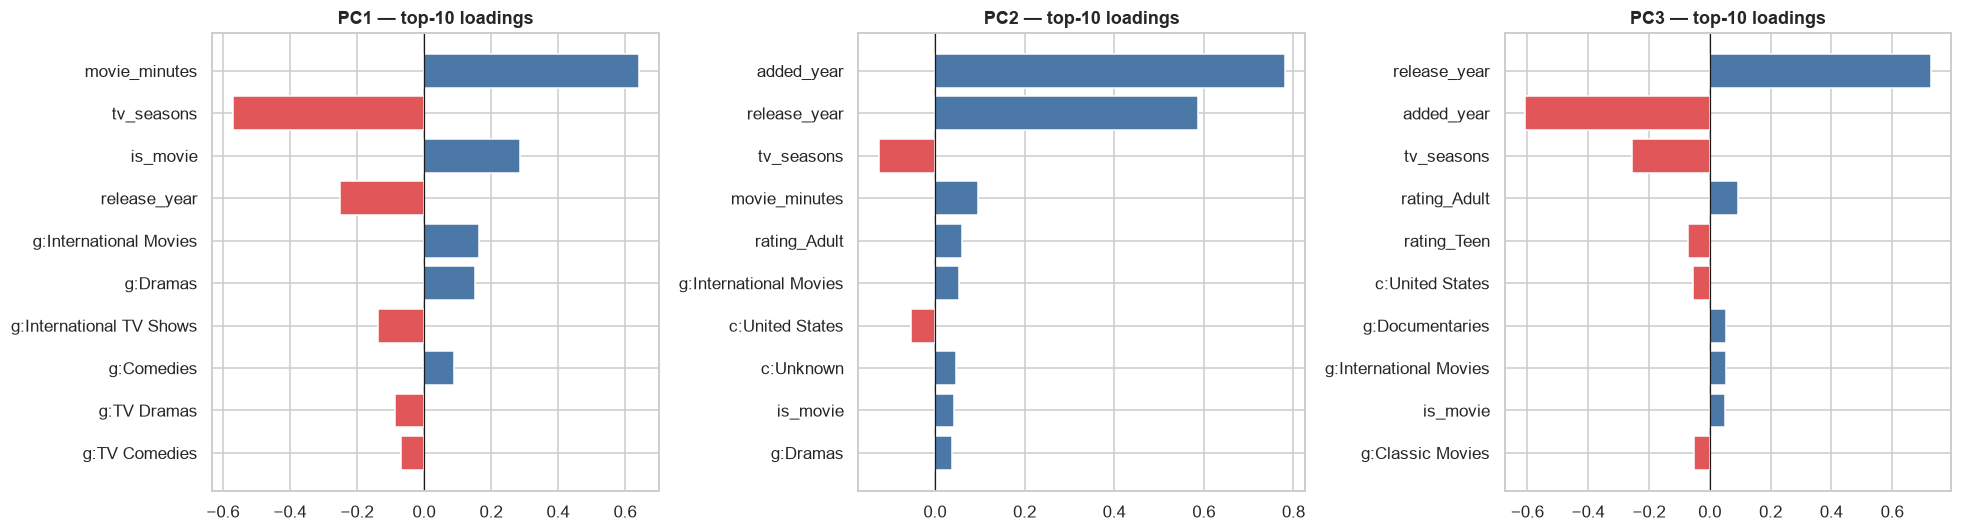

PC1: movie_minutes (+0.64), tv_seasons (-0.57), is_movie (+0.29), release_year (-0.25)
PC2: added_year (+0.78), release_year (+0.59), tv_seasons (-0.13), movie_minutes (+0.10)
PC3: release_year (+0.73), added_year (-0.61), tv_seasons (-0.26), rating_Adult (+0.09)


In [14]:
load = pd.DataFrame(pca.components_[:3].T, index=FEATURE_NAMES, columns=["PC1", "PC2", "PC3"])
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, pc in zip(axes, load.columns):
    s = load[pc].reindex(load[pc].abs().sort_values(ascending=False).head(10).index).iloc[::-1]
    ax.barh([i.replace("genre_", "g:").replace("country_", "c:") for i in s.index], s.values, color=["#E15759" if v < 0 else "#4C78A8" for v in s.values])
    ax.set_title(f"{pc} — top-10 loadings"); ax.axvline(0, color="k", lw=.8)
plt.tight_layout(); savefig("08_pca_loadings"); plt.show()
load.round(5).to_csv(f"{RES_DIR}/q3_pca_loadings_first3.csv")
for pc in load.columns:
    top = load[pc].reindex(load[pc].abs().sort_values(ascending=False).head(4).index)
    print(f"{pc}: " + ", ".join(f"{n} ({v:+.2f})" for n, v in top.items()))

### 3b-vi. (Extra) K-Means in the reduced space
Do the 2-D / 3-D PCA projections preserve the cluster structure? We re-run our K-Means on Z2 and Z3 and compare with the full-dimensional clustering (Adjusted Rand Index) and silhouette.

In [15]:
rows = [{"space": f"Full ({p}-D)", "silhouette": silhouette_score(X, labels, sample_size=3000, random_state=SEED), "ARI vs full-D": 1.0, "WCSS": km.inertia_}]
for nm, Z in [("PCA 3-D", Z3), ("PCA 2-D", Z2)]:
    mk = KMeansScratch(K_FINAL_USED, n_init=10, random_state=SEED).fit(Z)
    rows.append({"space": nm, "silhouette": silhouette_score(Z, mk.labels_, sample_size=3000, random_state=SEED),
                 "ARI vs full-D": adjusted_rand_score(labels, mk.labels_), "WCSS": mk.inertia_})
cmp_df = pd.DataFrame(rows).set_index("space"); display(cmp_df.round(4)); cmp_df.round(6).to_csv(f"{RES_DIR}/q3_kmeans_full_vs_pca.csv")

,silhouette,ARI vs full-D,WCSS
space,,,
Full (66-D),0.1485,1.0000,41917.8861
PCA 3-D,0.4079,0.9934,11637.2101
PCA 2-D,0.4278,0.6920,6994.9146


## 4. Reading guide for the written discussion
* **Elbow** — report the WCSS table for K=2…6, state where the curve bends (use both `03_elbow_curve` panels and the silhouette); admit if the elbow is soft and say why (binary/categorical-heavy data, no natural cluster count).
* **Clusters** — use `q3_cluster_profiles.csv` and `04_cluster_genre_heatmap`; give each cluster a short name (e.g. "Kids & family TV", "Documentaries", "International dramas") *only if the profile supports it*.
* **PCA** — report the number of PCs needed for 80/90/95 %, the variance kept by 2 and 3 PCs, and the loadings of PC1/PC2. For multi-hot data the variance is spread over many components, so low 2-D variance is expected and should be stated, not hidden.
* **Validation** — mention our implementations match scikit-learn (WCSS/ARI table, EVR equality), which demonstrates correctness.
* **Limitations** — Euclidean K-Means assumes spherical clusters; binary features are not ideal for it (K-Modes / Gower would be alternatives); results depend on the feature design.

In [16]:
with open(f"{RES_DIR}/q3_params.json", "w") as f:
    json.dump({"data_source": source, "n_titles": int(X.shape[0]), "n_features": int(X.shape[1]), "numeric_features": NUM_COLS,
               "n_genres": len(keep_genres), "countries": keep_countries, "use_text_features": USE_TEXT_FEATURES,
               "elbow_auto_2_6": int(knee_req), "elbow_auto_1_10": int(knee_ext), "best_silhouette_k_2_6": int(best_sil_k),
               "K_final": int(K_FINAL_USED), "pcs_for_80_90_95": {str(int(t * 100)): n for t, n in n_for.items()},
               "variance_2pcs": float(pca.cumulative_variance_[1]), "variance_3pcs": float(pca.cumulative_variance_[2])}, f, indent=2)
print("Saved metrics to", os.path.abspath(RES_DIR), "and figures to", os.path.abspath(FIG_DIR))

Saved metrics to C:\Users\user\OneDrive\Desktop\ml_assignment\results and figures to C:\Users\user\OneDrive\Desktop\ml_assignment\figures\q3
